In [1]:
import dynamicauc as dac
import pandas as pd
from benchmark_utils import run_benchmark_anarchy, plot_anarchy_results

### **Experiment A: Benchmarking Resilience to User Saturation**

This experiment evaluates how different bidding strategies adapt to **non-stationary user value** caused by ad fatigue. We compare the **FiPla (First-Price-Like)** baseline, an oracle policy that bids the exact expected reward, against a **Static Greedy** bidder and a **Random** baseline. 

We specifically measure the **Cumulative Net Utility**, which represents the total number of conversions generated by the campaign minus the total cost (payments) incurred in the auctions.

---

### **Key Concepts for Interpretation**

* **Cumulative Net Utility ($U_T$):** Mathematically, this is defined as $U_T = \sum_{i: t_i \le T} (R_{i} - p_i)$, where $R_{i}$ is the count of realized conversions for win $i$, and $p_i$ is the price paid. It captures the overall profitability of the campaign.

* **Saturation Regime:** The `saturation_scale` controls how many ad views a user can "absorb" before their conversion probability drops.

* **The Goal:** A robust policy should maintain a steady growth in utility; a plateauing curve indicates that the policy is "burning" the user's receptiveness faster than it can recover.

In [6]:
policies = {
            "FiPla": dac.FiPlaPolicy(),
            "Static Greedy": dac.ConstantPolicy(bid_value=0.3),
            "Random": dac.RandomPolicy(max_bid=1.0)
        }

saturation_scales = [0.5, 1.0, 2.0, 10.0]
        
# Exécution
df_results = run_benchmark_anarchy(policies=policies, saturation_scales=saturation_scales)
df_results

,t,utility,net_reward,won,policy,sat_scale
0,3.190863,0.538912,0.538912,True,FiPla,0.5
1,4.708868,0.538912,0.000000,False,FiPla,0.5
2,6.405682,0.538912,0.000000,False,FiPla,0.5
3,7.714475,0.371555,-0.167356,True,FiPla,0.5
4,9.731936,0.371555,0.000000,False,FiPla,0.5
...,...,...,...,...,...,...
19,40.369892,0.460853,0.000000,False,Random,10.0
20,46.457539,0.460853,0.000000,False,Random,10.0
21,48.649422,0.460853,0.000000,False,Random,10.0
22,49.129749,0.460853,0.000000,False,Random,10.0


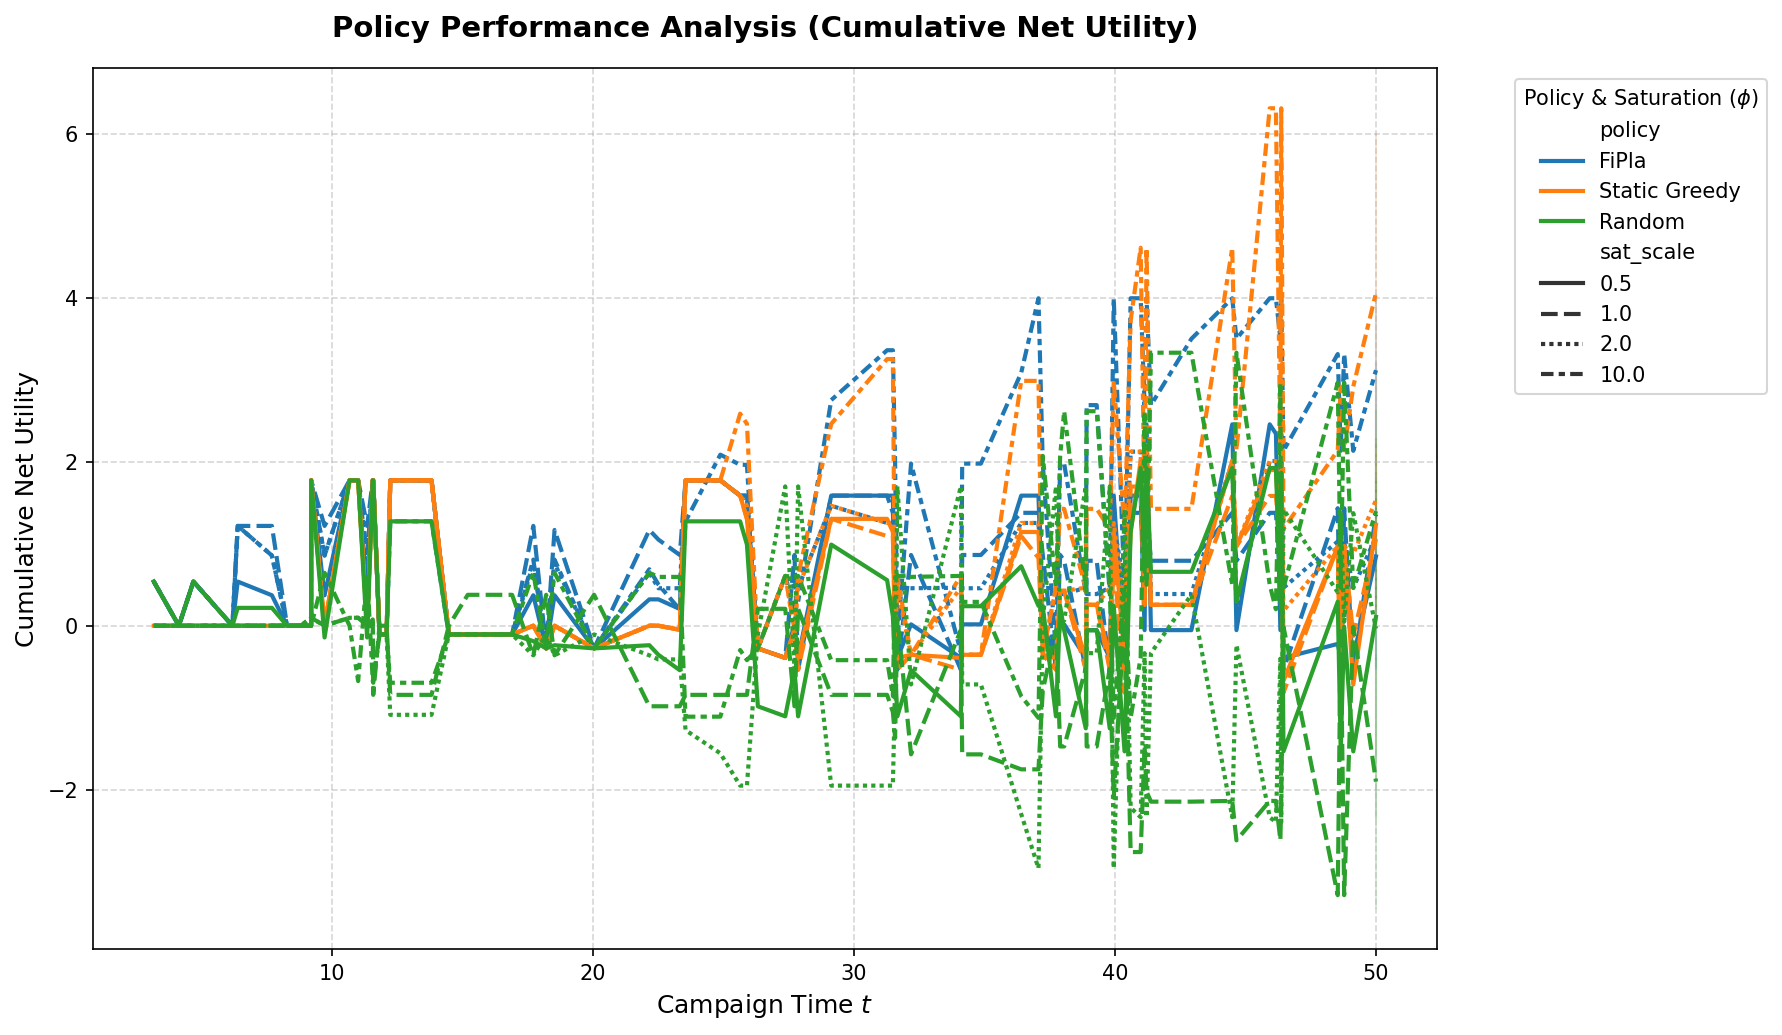

In [7]:
plot_anarchy_results(df_results, key='utility')

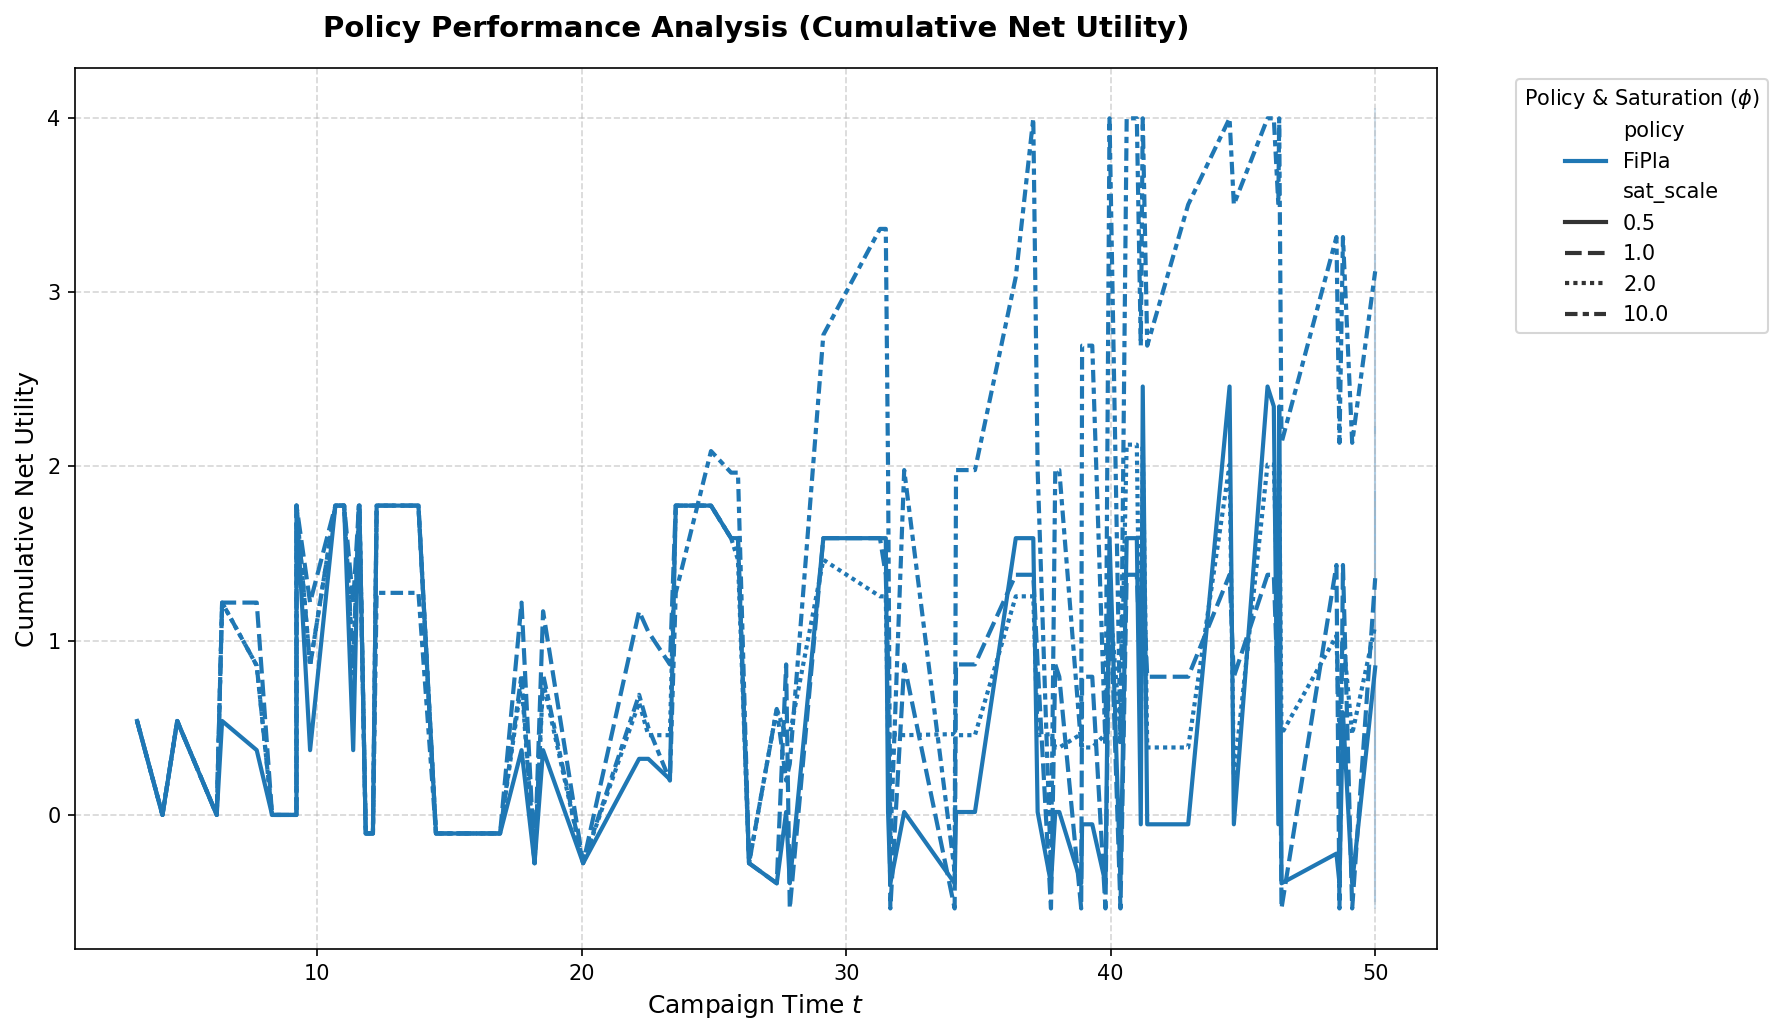

In [8]:
plot_anarchy_results(df_results, key='utility', policies=["FiPla"])

By varying the `saturation_scale` parameter, we observe the "Price of Anarchy": in regimes with high fatigue (small scale), the truthful FiPla policy often over-exposes the user early on, leading to diminishing marginal returns and sub-optimal long-term efficiency compared to more "patient" strategies.

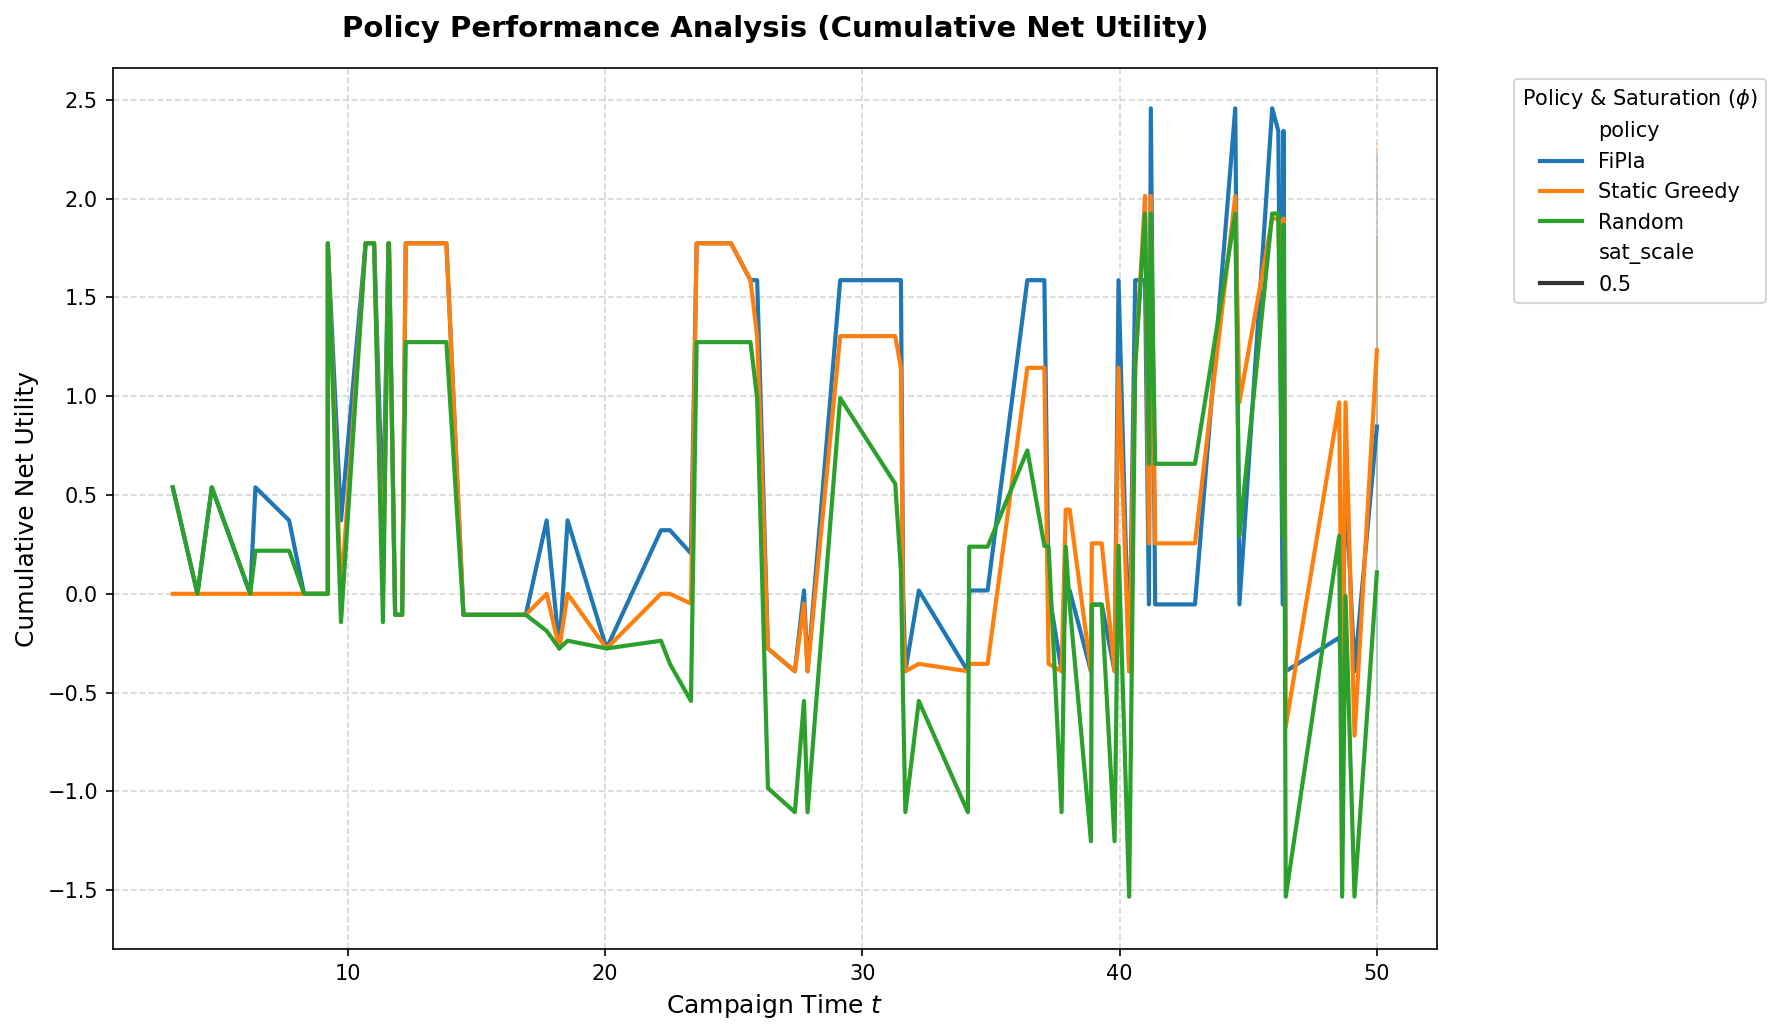

In [10]:
plot_anarchy_results(df_results, key='utility', sat_scales=[0.5])